# Step 7: Ensembles

Calibrated members, LR and gated LightGBM stacking fitted on validation with 5-fold cross-fitting, optional MBR decision rules. Code: `experiments/01_ensemble_voting_mbr/`, `experiments/11_full_convergence/ensemble_v3.py`. Details: `docs/steps/07_ensembles.md`.

In [1]:
# Imports and paths
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
import nbutils as U
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
print("model prediction groups found:", len(list(U.PRED_DIR.glob("*/sarc_random__test.parquet"))))

model prediction groups found: 22


## 7.1 Saved results for each configuration

In [2]:
# Saved results per configuration
CONFIGS = {"compliant + scratch NN (submitted)": "ensemble_compliant_with_scratch",
           "compliant + scratch NN, no subreddit member": "ensemble_compliant_with_scratch_no_subreddit",
           "compliant, no scratch NN": "ensemble_no_pretrained",
           "with RoBERTa (reference only)": "ensemble_final"}
rows = []
for name, folder in CONFIGS.items():
    df = pd.read_csv(U.EXP / "11_full_convergence/results" / folder / "ensemble_results.csv")
    for s, g in df.groupby("set"):
        g = g.set_index("method")
        rows.append({"configuration": name, "set": s, "members": int(g["n_members"].iloc[0]),
                     **{m: g.loc[m, "test_roc_auc"] for m in ["best_single", "soft_vote", "greedy_select", "stack_lr", "stack_lgbm_meta", "blend_meta_lr"] if m in g.index}})
U.show(pd.DataFrame(rows))

,configuration,set,members,best_single,soft_vote,greedy_select,stack_lr,stack_lgbm_meta,blend_meta_lr
0,compliant + scratch NN (submitted),sarc_random,24,0.8296,0.8288,0.8384,0.8416,0.8417,0.8420
1,compliant + scratch NN (submitted),sarc_subreddit,22,0.8226,0.8228,0.8326,0.8335,0.8335,0.8340
2,"compliant + scratch NN, no subreddit member",sarc_random,23,0.8296,0.8288,0.8384,0.8412,0.8409,0.8414
3,"compliant + scratch NN, no subreddit member",sarc_subreddit,22,0.8226,0.8228,0.8326,0.8335,0.8335,0.8340
4,"compliant, no scratch NN",sarc_random,22,0.8296,0.8252,0.8323,0.8346,0.8347,0.8350
5,"compliant, no scratch NN",sarc_subreddit,20,0.8226,0.8191,0.8255,0.8265,0.8263,0.8268
6,with RoBERTa (reference only),sarc_random,28,0.8809,0.8476,0.8838,0.8859,0.8858,0.8861
7,with RoBERTa (reference only),sarc_subreddit,24,0.8762,0.8348,0.8762,0.8790,0.8789,0.8791


In [3]:
# Submitted configuration in detail
sub = pd.read_csv(U.EXP / "11_full_convergence/results/ensemble_compliant_with_scratch/ensemble_results.csv")
U.show(sub[sub.set == "sarc_random"][["method", "val_auc_oof", "test_roc_auc", "test_precision", "test_recall", "test_f1", "test_p75_recall", "d_auc_vs_best_single", "ci_low", "ci_high"]])

,method,val_auc_oof,test_roc_auc,test_precision,test_recall,test_f1,test_p75_recall,d_auc_vs_best_single,ci_low,ci_high
0,best_single,0.8256,0.8296,0.7743,0.7215,0.7470,0.7511,0.0000,0.0000,0.0000
1,soft_vote,0.8254,0.8288,0.7773,0.7148,0.7448,0.7521,-0.0008,-0.0015,-0.0001
2,greedy_select,0.8343,0.8384,0.7814,0.7314,0.7556,0.7716,0.0087,0.0081,0.0095
3,stack_lr,0.8374,0.8416,0.7844,0.7335,0.7581,0.7784,0.0120,0.0113,0.0127
4,stack_lr_l1,0.8374,0.8416,0.7845,0.7333,0.7581,0.7783,0.0120,0.0113,0.0127
5,shapley_stack,0.8374,0.8416,0.7844,0.7335,0.7581,0.7784,0.0120,0.0113,0.0127
6,stack_lgbm_meta,0.8373,0.8417,0.7852,0.7330,0.7582,0.7801,0.0120,0.0113,0.0127
7,blend_meta_lr,0.8378,0.8420,0.7850,0.7334,0.7583,0.7793,0.0124,0.0117,0.0131
8,blend_meta_lr+mbr_expected_f1,NaN,0.8420,0.7219,0.8297,0.7720,NaN,NaN,NaN,NaN
9,blend_meta_lr+mbr_expected_prec75,NaN,0.8420,0.7542,0.7825,0.7681,NaN,NaN,NaN,NaN


## 7.2 Live re-run: logistic-regression stacking on compliant members
Same recipe as the scripts (Platt calibration on validation → logits → 5-fold out-of-fold LR → refit on all of validation → score test once).

In [4]:
# Live LR stacking on compliant members
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
test, val = U.predictions("sarc_random")
DROP = {"cnb_reply_tfidf", "cnb_reply_tfidf_surface", "lgbm_base_repro"}
members = [m for m in U.model_columns(test) if U.info(m)["compliant"] and m in val and m not in DROP]
print(len(members), "compliant members")
def to_logit(x):
    x = np.asarray(x, float)
    if x.min() >= 0 and x.max() <= 1: x = np.clip(x, 1e-6, 1 - 1e-6); x = np.log(x / (1 - x))
    return x
yv, yt = val["label"].to_numpy(), test["label"].to_numpy()
Zv, Zt = [], []
for m in members:
    xv, xt = to_logit(val[m]).reshape(-1, 1), to_logit(test[m]).reshape(-1, 1)
    cal = LogisticRegression().fit(xv, yv)
    Zv.append(cal.decision_function(xv)); Zt.append(cal.decision_function(xt))
Zv, Zt = np.column_stack(Zv), np.column_stack(Zt)
oof = np.zeros(len(yv))
for tr, te in StratifiedKFold(5, shuffle=True, random_state=3244).split(Zv, yv):
    oof[te] = LogisticRegression(C=1.0, max_iter=2000).fit(Zv[tr], yv[tr]).decision_function(Zv[te])
meta = LogisticRegression(C=1.0, max_iter=2000).fit(Zv, yv)
p_stack = meta.decision_function(Zt); p_soft = (1 / (1 + np.exp(-Zt))).mean(1)
best = max(members, key=lambda m: roc_auc_score(yv, val[m]))
print(f"best single (chosen on val): {best}  test AUC {roc_auc_score(yt, test[best]):.4f}")
print(f"soft vote                     test AUC {roc_auc_score(yt, p_soft):.4f}")
print(f"LR stacking  OOF val AUC {roc_auc_score(yv, oof):.4f} | test AUC {roc_auc_score(yt, p_stack):.4f}  (saved script: 0.8416)")

24 compliant members


best single (chosen on val): lgbm_lrscore_cues_contrast  test AUC 0.8296
soft vote                     test AUC 0.8288
LR stacking  OOF val AUC 0.8374 | test AUC 0.8416  (saved script: 0.8416)


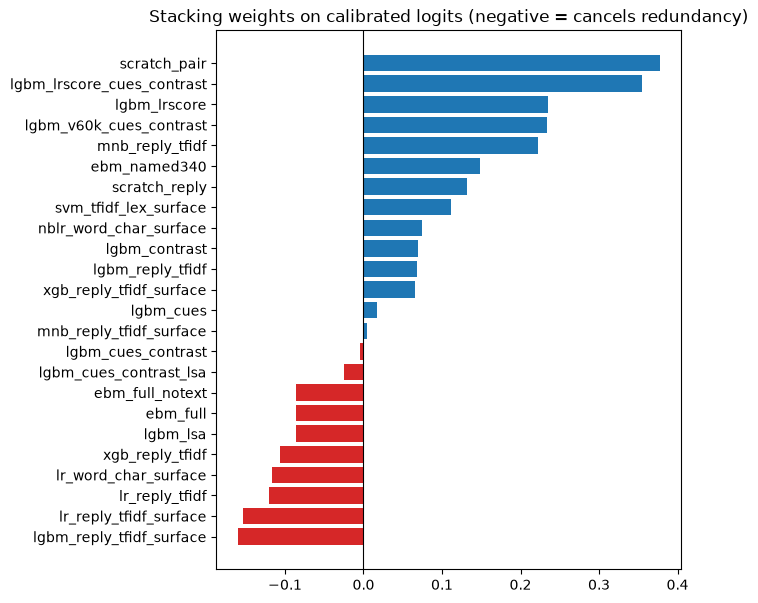

In [5]:
# Stacking weights
w = pd.Series(meta.coef_[0], index=members).sort_values()
fig, ax = plt.subplots(figsize=(6, 7)); ax.barh(w.index, w.values, color=["tab:red" if v < 0 else "tab:blue" for v in w.values])
ax.axvline(0, color="k", lw=0.8); ax.set_title("Stacking weights on calibrated logits (negative = cancels redundancy)")
U.savefig(fig, "S07_stacking_weights.png"); plt.show()

## 7.3 Shapley contributions of members (saved)

In [6]:
# Shapley values and greedy weights
det = U.read_json(U.EXP / "11_full_convergence/results/ensemble_compliant_with_scratch/ensemble_details.json")["sarc_random"]
sh = det["shapley"]
sh = pd.Series(sh.get("values", sh) if isinstance(sh, dict) else sh)
print("greedy selection weights:", det["greedy_weights"])
sh.sort_values(ascending=False).head(10) if sh.dtype != object else sh

greedy selection weights: {'scratch_pair': 0.5, 'lgbm_lrscore_cues_contrast': 0.5}


scratch_pair               0.006211
scratch_reply              0.002296
mnb_reply_tfidf            0.000661
ebm_named340               0.000583
lgbm_v60k_cues_contrast    0.000535
nblr_word_char_surface     0.000254
xgb_reply_tfidf_surface    0.000235
lgbm_lrscore               0.000186
lgbm_contrast              0.000186
lr_reply_tfidf_surface     0.000128
dtype: float64

## 7.4 Takeaways

- **Submitted result: compliant stacking (24 members incl. the from-scratch networks) 0.8420 on sarc_random, 0.8340 on sarc_subreddit**, +0.0346 over the baseline and +0.0124 over the best compliant single model.
- Soft voting does not help (weak, correlated members drag it down); learned weights — including negative ones — are required.
- All learned combiners (L2, L1, Shapley pruning, gated LightGBM, their blend) land within 0.001 of each other: the combiner is saturated. The gain comes from adding a member that errs differently (the scratch ESIM: +0.007), not from a fancier combiner.
- Dropping the only subreddit-using member costs ≈0.0006, so the submission can be stated as subreddit-free.
- MBR expected-F1 decision lifts F1 from 0.758 to 0.772 without touching test labels.
- With RoBERTa (reference only) the same framework reaches 0.8861.